# 01 · Easy synthetic data

Answers Q1–Q6 on **easy** data (5 seeds per cell; ladder in notebook 00). Each section:
question and outcomes → run → table/plot → the outcome picked by the pre-registered rule.
All raw results are saved to `notebooks_sharedness/results/easy_*.csv`.

In [1]:
import os, sys, warnings
os.environ["TQDM_DISABLE"] = "1"
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks_sharedness" else os.getcwd()
sys.path.insert(0, ROOT)
os.chdir(ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
from sharedness import experiments as ex, metrics as mt
from sharedness.data import make_view_data, H_EASY, pattern_for

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook")
RESULTS = os.path.join(ROOT, "notebooks_sharedness", "results")
os.makedirs(RESULTS, exist_ok=True)

def outcome(code_text, title="Observed outcome"):
    code, text = code_text
    display(Markdown(f"> **{title}: {code}** — {text}"))
    return code

LEVEL = "easy"
SEEDS = range(5)

## Q1 — Can CohortFACTM learn how often cohorts differ?

**Why we ask.** The cohort switch rate $\pi$ is fixed at 0.5 in CohortFACTM. If it can be learned, the model
reports how many cohorts actually have their own mean; if the learned value is biased, we need to know why
before trusting any cohort read-out.

**Setup.**

- **Samples.** $C=6$ cohorts, $n_c=50$ samples each, $N=300$. (This is $C$ larger and $n_c$ smaller than the
  other questions, because Q1 is about cohorts, not views.)
- **Factors.** $K$ as in this level. Each true factor score is $z_{nk}=\gamma^\ast_{ck}\delta^\ast_{ck}+\varepsilon$:
  a cohort either sits at the common centre or is shifted by $\delta^\ast=\pm2$.
- **The knob.** The true switch rate $\pi^\ast$ — the fraction of $(c,k)$ pairs that are shifted — is set to
  **0.1, 0.3, 0.6** in turn. These are the numbers the learned $\mathbb E[\pi]$ should recover.
- **What counts as a real shift.** The data are centred on the grand mean, so a switch can only see a cohort's
  mean *relative to the grand mean*. The truth we score against is therefore
  $G^{\text{eff}}_{ck}=\mathbb 1\{|\bar z_{ck}-\bar z_{\cdot k}|>1\}$, not the raw $\gamma^\ast$. $G^{\text{eff}}$ can differ
  from $\pi^\ast$ (e.g. when one cohort shifts, the others move a little the other way).
- **Repeats.** 5 seeds per rate.

**What we fit.** Three cohort priors, all with ARD loadings:
1. **$\pi=0.5$ fixed** — CohortFACTM as it is today.
2. **$\pi$ learned, current factorisation** $q(\gamma)q(\delta)$ — $q(\pi)=\mathrm{Beta}(1+\sum_{c,k}\mathbb E\gamma_{ck},\,1+CK-\sum\mathbb E\gamma_{ck})$.
3. **$\pi$ learned, paired factorisation** $q(\gamma)q(\delta\mid\gamma)$ — the fix proposed in the model document.

**What we measure.**

- **$\mathbb E[\pi\mid Y]$** vs the true rate (effective rate on synthetic data). Good = close to the diagonal.
- **$\gamma$ AUC** $=P(\mathbb E\gamma_{ck}>\mathbb E\gamma_{c'k'}\mid G^{\text{eff}}_{ck}=1,\,G^{\text{eff}}_{c'k'}=0)$: does
  $\mathbb E\gamma$ rank the real shifts above the non-shifts? $1$ perfect, $0.5$ chance.
- **null $\mathbb E\gamma$** = mean $\mathbb E\gamma$ where the truth is 0 (should be low); **alt** = where it is 1.

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** Learnable | max $|\mathbb E\pi-\pi^\ast|<0.15$ and $\mathbb E\pi$ rises with $\pi^\ast$ (slope $>0.5$) | the data carry the rate | keep $\pi$ learnable |
| **O2** Drifts to 1 | $\mathbb E\pi>0.8$ whatever $\pi^\ast$ is | switches that should be off are not pushed off | the factorisation, not the formula, is at fault — try the paired one |
| **O3** Prior-dominated | $\mathbb E\pi$ moves $<0.2$ across all $\pi^\ast$ | too few switches ($CK$) to learn from | leave $\pi$ fixed |
| **O4** Partial | anything else (moves with the truth but biased) | the rate is partly recoverable | report the bias and prefer the arm with the smallest one |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

In [2]:
q1 = ex.run_q1(LEVEL, seeds=SEEDS)
q1.to_csv(os.path.join(RESULTS, f"{LEVEL}_q1.csv"), index=False)
summary = (q1.groupby(["arm", "rate"])
             [["true_rate", "E_pi", "sd_pi", "mean_gamma_null", "mean_gamma_alt", "auc_gamma", "monotone"]]
             .mean())
summary

true_rate   E_pi  sd_pi  mean_gamma_null  \
arm                    rate                                             
fixed pi=0.5 (current) 0.1       0.100  0.500  0.000            0.256   
                       0.3       0.308  0.500  0.000            0.388   
                       0.6       0.533  0.500  0.000            0.586   
learned pi (current q) 0.1       0.100  0.248  0.070            0.155   
                       0.3       0.308  0.629  0.072            0.566   
                       0.6       0.533  0.956  0.040            0.990   
learned pi (paired q)  0.1       0.100  0.240  0.078            0.137   
                       0.3       0.308  0.585  0.090            0.479   
                       0.6       0.533  0.794  0.077            0.714   

                             mean_gamma_alt  auc_gamma  monotone  
arm                    rate                                       
fixed pi=0.5 (current) 0.1            1.000      1.000       1.0  
                       0.3            0.789      0.843       1.0  
                       0.6            0.806      0.761       1.0  
learned pi (current q) 0.1            1.000      1.000       1.0  
                       0.3            0.874      0.865       1.0  
                       0.6            0.998      0.802       1.0  
learned pi (paired q)  0.1            1.000      1.000       1.0  
                       0.3            0.915      0.903       1.0  
                       0.6            0.920      0.804       1.0

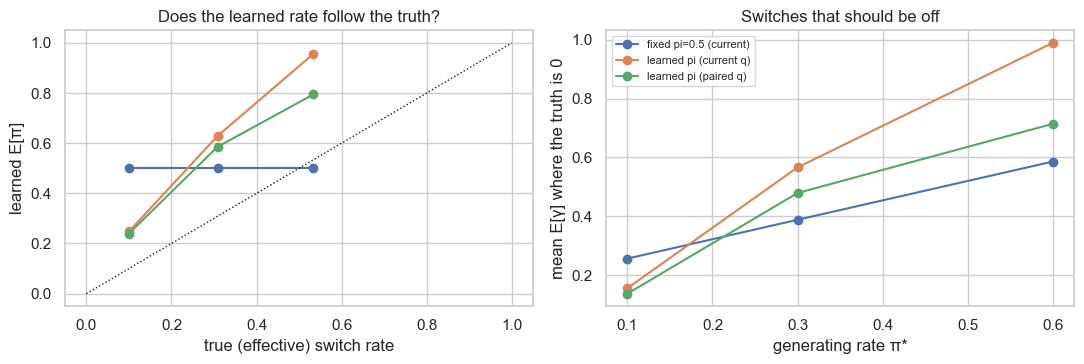

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for arm, d in q1.groupby("arm"):
    g = d.groupby("rate")[["true_rate", "E_pi"]].mean()
    axes[0].plot(g["true_rate"], g["E_pi"], "o-", label=arm)
    g2 = d.groupby("rate")["mean_gamma_null"].mean()
    axes[1].plot(g.index, g2, "o-", label=arm)
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_xlabel("true (effective) switch rate")
axes[0].set_ylabel("learned E[π]"); axes[0].set_title("Does the learned rate follow the truth?")
axes[1].set_xlabel("generating rate π*"); axes[1].set_ylabel("mean E[γ] where the truth is 0")
axes[1].set_title("Switches that should be off"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
for arm in ["learned pi (current q)", "learned pi (paired q)"]:
    outcome(ex.decide_q1(q1, arm), title=f"Observed outcome [{arm}]")

> **Observed outcome [learned pi (current q)]: O4** — PARTIAL: E[pi] moves with the truth (slope 1.63) but is biased (max error 0.42).

> **Observed outcome [learned pi (paired q)]: O4** — PARTIAL: E[pi] moves with the truth (slope 1.27) but is biased (max error 0.28).

## Q2 — Does a plain fit already show which factors are shared?

**Why we ask.** If an ordinary fit already reveals the shared/private pattern, no new model is needed to *see* it —
only (later) to *identify* it. This tells us whether the hard part is reading the pattern or finding the factors.

**Setup.**

- **Samples / views / noise / loadings** exactly as this level's data (stated at the top of the notebook: easy
  = 4 views $\times$ 30 features, $N=300$, noise 0.5, independent loadings; hard = 4 views of 80/40/15/10
  features, $N=150$, noise 1.2, correlated loadings, one weak factor, 2 surplus fitted factors).
- **True pattern $H$** (views $\times$ factors) is the matrix drawn at the top of notebook 00. We know it, so we
  can score recovery.

**What we fit.** Two loadings priors: **no prior** ($w\sim\mathcal N(0,1)$) and **ARD**. No cohort structure.

**What we measure.**

- **Variance share** $r_{mk}=\lVert\mathbb E z_{\cdot k}\,\mathbb E w^{(m)\top}_{\cdot k}\rVert_F^2/\lVert Y^{(m)}\rVert_F^2$:
  the fraction of view $m$'s variance carried by factor $k$. Normalise per factor to activity $a_{mk}\in[0,1]$.
- **Pattern AUC** $=P(a_{mk}>a_{m'k'}\mid H_{mk}=1,\,H_{m'k'}=0)$, after matching fitted to true factors
  (Hungarian on $|\mathrm{corr}|$). Threshold-free; $1$ perfect, $0.5$ chance. We report it with and without ARD.

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** Yes, any fit | AUC $\ge0.95$ with and without ARD | sharedness is a read-out of the fit | no new model needed to see the pattern |
| **O2** Yes, with ARD | AUC $\ge0.95$ only with ARD | ARD is what makes the pattern readable | use ARD loadings when reading sharedness |
| **O3** Partly | best AUC in $[0.75,0.95)$ | some cells are read wrongly | inspect leaks (private read as shared) vs misses |
| **O4** No | best AUC $<0.75$ | the fit does not expose the pattern | the bottleneck is elsewhere (see Q2b) |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

In [5]:
q2 = ex.run_q2(LEVEL, seeds=SEEDS)
q2[["arm", "seed", "auc_r", "auc_ard", "leak_r", "miss_r", "exact_r", "min_corr", "surplus_share",
    "monotone", "n_iter"]].to_csv(os.path.join(RESULTS, f"{LEVEL}_q2.csv"), index=False)
q2.groupby("arm")[["auc_r", "auc_ard", "leak_r", "miss_r", "exact_r", "min_corr", "surplus_share"]].mean()

,auc_r,auc_ard,leak_r,miss_r,exact_r,min_corr,surplus_share
arm,,,,,,,
ARD,0.997,0.997,0.4,0.4,3.4,0.856,0.0
ARD_truthstart,1.000,1.000,0.0,0.0,4.0,0.991,0.0
NONE,0.975,NaN,0.8,0.2,3.2,0.727,0.0


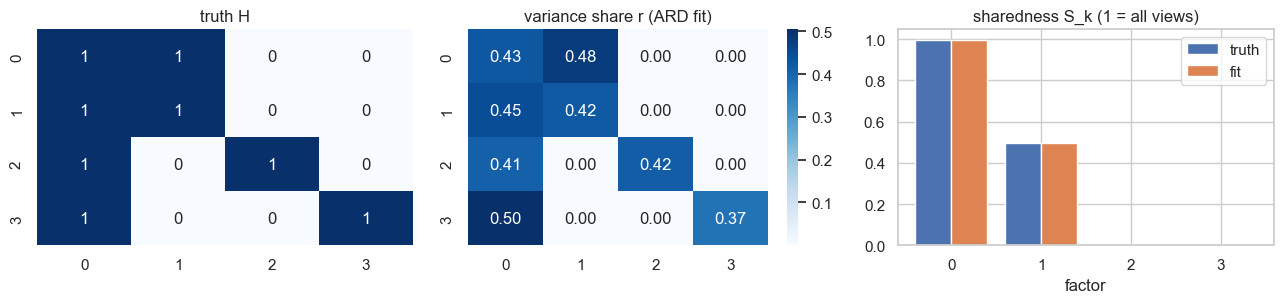

In [6]:
# One fit, drawn: the variance-share matrix next to the truth.
row = q2[(q2.arm == "ARD") & (q2.seed == 0)].iloc[0]
ds0, _ = ex.level_data(LEVEL, 0)
r = row["r"][:, row["match_idx"]]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
sns.heatmap(ds0.H, ax=axes[0], cmap="Blues", cbar=False, annot=True); axes[0].set_title("truth H")
sns.heatmap(r, ax=axes[1], cmap="Blues", annot=True, fmt=".2f"); axes[1].set_title("variance share r (ARD fit)")
S_true = mt.sharedness_entropy(mt.variance_share(ds0.Z, ds0.Ws, ds0.Ys))
S_fit = row["S_fit"][row["match_idx"]]
axes[2].bar(np.arange(len(S_true)) - .2, S_true, .4, label="truth")
axes[2].bar(np.arange(len(S_fit)) + .2, S_fit, .4, label="fit")
axes[2].set_title("sharedness S_k (1 = all views)"); axes[2].set_xlabel("factor"); axes[2].legend()
plt.tight_layout(); plt.show()

In [7]:
outcome(ex.decide_q2(q2))

> **Observed outcome: O1** — YES, ANY FIT: the variance share reads the pattern with or without ARD (AUC 0.97 without, 1.00 with).

'O1'

## Q2b — When the fit lands on the wrong factors, is it the optimiser or the model?

**Why we ask.** If the model's objective (ELBO) *prefers* the true factors but the algorithm fails to reach them, the
fix is better optimisation (cheap). If the ELBO itself prefers a rotated answer, the fix is new theory (hard).
Everything downstream depends on which it is.

**Setup.**

- **Same data as Q2.** Look only at seeds where the ordinary ARD fit (from the usual PCA start) missed the true
  factors: $\min_k|\mathrm{corr}(\hat z_k,z^\ast_k)|<0.9$.
- For each such seed, **refit a second time starting exactly at the truth** $(Z^\ast,W^\ast)$, and compare the two
  fits' final ELBO.

**What we fit.** ARD loadings from two starts: the usual PCA start, and the true $(Z^\ast,W^\ast)$.

**What we measure.**

- **$\Delta_{\text{start}}=\mathrm{ELBO}_{\text{truth start}}-\mathrm{ELBO}_{\text{PCA start}}$** (nats). Positive means the
  model scores the truth higher than the rotated answer it actually found.
- Whether the truth-started fit **keeps** the true axes (does not drift back to the rotated answer).

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O0** Not needed | every ARD fit already found the true axes | no problem to diagnose | move on |
| **O1** Optimiser | $\Delta_{\text{start}}>10$ nats and the truth start keeps the true axes | the ELBO prefers the truth; the algorithm just doesn't reach it | better initialisation / multi-start fixes it |
| **O2** Model | $\Delta_{\text{start}}<-10$, or the truth start drifts away | the ELBO itself prefers a rotation | an identification result is needed (mean-field artefact regime) |
| **O3** Flat | $|\Delta_{\text{start}}|\le10$ | the two solutions are indistinguishable to the ELBO | the rotation is (nearly) unidentified |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

In [8]:
piv = q2[q2.arm.isin(["ARD", "ARD_truthstart"])].pivot(index="seed", columns="arm",
                                                       values=["elbo", "min_corr"])
piv[("elbo", "truth − PCA start")] = piv[("elbo", "ARD_truthstart")] - piv[("elbo", "ARD")]
piv

elbo                min_corr                             elbo
arm         ARD ARD_truthstart      ARD ARD_truthstart truth − PCA start
seed                                                                    
0    -31679.515     -31541.318    0.991          0.991           138.197
1    -32181.515     -31453.412    0.667          0.989           728.103
2    -31786.832     -31585.503    0.993          0.993           201.329
3    -31668.634     -31440.699    0.800          0.992           227.935
4    -31928.983     -31501.664    0.828          0.992           427.318

In [9]:
outcome(ex.decide_q2b(q2))

> **Observed outcome: O1** — OPTIMISER: in 3 seed(s) where ARD missed the axes, starting at the truth gives an ELBO 461 nats higher and stays there (100%). The model prefers the truth; CAVI does not reach it.

'O1'

## Q3 — How many views are needed before shared-vs-private is a meaningful question?

**Why we ask.** With 2 views there are only 3 possible patterns; with 4 there are 15. We need to know whether few
views make the pattern merely *coarse* or actually *hard to detect* — this decides whether COVID ($M=2$) is a
usable test bed.

**Setup.**

- **A ladder of view counts** $M\in\{2,3,4,6\}$. For each $M$ the true pattern has one fully shared factor, one
  factor in views 1–2 (when $M>2$), and one factor private to each view.
- Feature counts per view: 30 (easy) or spread 80…10 (hard); other settings as this level.
- **Repeats.** 5 seeds per $M$.
- Plus a **no-fitting table**: the posterior sd of a per-factor rate learned from only $M$ switches,
  $\mathrm{Beta}(1+s_k,1+M-s_k)$ — shows how uncertain $\pi_k$ must be when $M$ is small, before any experiment.

**What we fit.** ARD loadings, no cohort structure, one fit per $(M,\text{seed})$.

**What we measure.** **AUC of ARD activity against $H$** (as in Q2), averaged over seeds, for each $M$. Good = high and
flat across $M$; a rise with $M$ means more views help detection.

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** M does not limit detection | AUC $\ge0.95$ at every $M$ | even $M=2$ detects the pattern, just coarsely | COVID is usable; more views only add resolution |
| **O2** More views help | AUC rises by $\ge0.05$ from the smallest to the largest $M$ | detection improves with views | prefer the four-view data over COVID |
| **O3** More views hurt | AUC falls by $\ge0.05$ | more private factors split the signal | cap the number of views / factors |
| **O4** Flat but imperfect | otherwise | detection is limited by something other than $M$ | look at noise / factor strength instead |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

In [10]:
q3 = ex.run_q3(LEVEL, seeds=SEEDS)
q3[["M", "seed", "auc_ard", "auc_r", "exact_r", "min_corr"]].to_csv(
    os.path.join(RESULTS, f"{LEVEL}_q3.csv"), index=False)
q3.groupby("M")[["auc_ard", "auc_r", "exact_r", "min_corr"]].mean()

,auc_ard,auc_r,exact_r,min_corr
M,,,,
2,1.000,1.000,3.0,0.794
3,0.996,1.000,4.6,0.771
4,0.983,0.971,4.4,0.761
6,0.981,0.978,6.2,0.661


In [11]:
outcome(ex.decide_q3(q3))

> **Observed outcome: O1** — M DOES NOT LIMIT DETECTION: AUC >= 0.95 at every M (M=2: 1.00). With M = 2 the question is answerable, just coarse (3 patterns).

'O1'

## Q4 — Does an explicit on/off view switch beat ARD's soft dials?

**Why we ask.** ARD turns a factor's loadings in a view *down* but never fully *off*, so any yes/no call needs an
arbitrary cutoff. A real switch $h_{mk}$ would give a direct answer — if it is identifiable.

**Setup.**

- **Same data as Q2** (this level). We know $H$, so we can check the switch's calls.
- The switch is $w^{(m)}_{\cdot k}=h_{mk}V^{(m)}_{\cdot k}$, $h_{mk}\sim\mathrm{Bern}(\pi)$, one Bernoulli per (view, factor).

**What we fit.** Four arms: **ARD** (reference, no switch); **switch, cold start**; **switch, warm start** (started from a
converged ARD fit); **switch, warm start + fixed slab** (slab precision $\alpha\equiv1$ instead of learned ARD).

**What we measure.**

- **Switch AUC** of $\mathbb E[h]$ against $H$ (as in Q2).
- **Decisiveness** = share of $\mathbb E[h_{mk}]$ outside $(0.1,0.9)$ — are the calls confident?
- **Switches on** = share with $\mathbb E[h]>0.5$ (true value 50% in the synthetic pattern).
- **Leaks** (private called shared) and **misses** (shared called absent).

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** Cleaner | best switch AUC $\ge$ ARD$-0.02$, $\ge0.9$, and $\ge90\%$ decisive | the switch gives sharper correct calls | worth adding as a diagnostic |
| **O2** Switch stays on | $\ge95\%$ of switches on in the best arm | $h$ cannot tell itself apart from a shrunk slab ($\alpha\to\infty$ and $h=0$ look the same) | drop the switch or use a fixed slab |
| **O3** Worse than ARD | best switch AUC $<$ ARD$-0.05$ | the switch harms recovery | keep ARD |
| **O4** Mixed | otherwise | it depends on the slab | report per arm |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

In [12]:
q4 = ex.run_q4(LEVEL, seeds=SEEDS)
q4["on_share"] = q4["E_h"].map(lambda x: np.nan if not isinstance(x, np.ndarray) else float(np.mean(x > .5)))
q4["pi_mean"] = q4["pi"].map(lambda x: np.nan if not isinstance(x, dict) else x["mean"][0])
cols = ["arm", "seed", "auc_ard", "auc_h", "decisive_h", "leak_h", "miss_h", "on_share", "pi_mean",
        "min_corr", "elbo", "monotone", "n_iter"]
q4[[c for c in cols if c in q4]].to_csv(os.path.join(RESULTS, f"{LEVEL}_q4.csv"), index=False)
q4.groupby("arm")[[c for c in cols[2:] if c in q4]].mean()

,auc_ard,auc_h,decisive_h,leak_h,miss_h,on_share,pi_mean,min_corr,elbo,monotone,n_iter
arm,,,,,,,,,,,
ARD,0.997,NaN,NaN,NaN,NaN,NaN,NaN,0.856,-31849.096,1.0,401.0
switch_cold,0.967,0.85,0.925,5.6,0.0,0.850,0.790,0.864,-31853.031,1.0,401.0
switch_warm,1.000,0.95,0.975,7.4,0.0,0.963,0.887,0.944,-31591.889,1.0,400.0
switch_warm_fixedslab,NaN,0.85,1.000,2.4,0.0,0.650,0.633,0.853,-31227.649,1.0,400.0


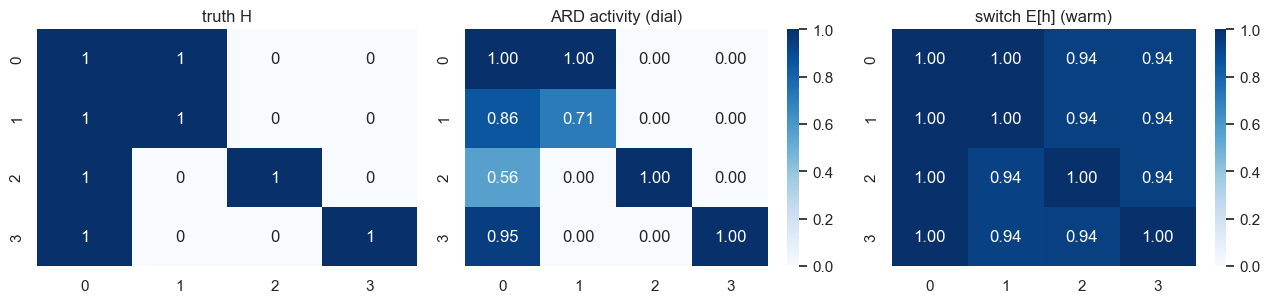

In [13]:
row = q4[(q4.arm == "switch_warm") & (q4.seed == 0)].iloc[0]
ds0, _ = ex.level_data(LEVEL, 0)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
sns.heatmap(ds0.H, ax=axes[0], cmap="Blues", cbar=False, annot=True); axes[0].set_title("truth H")
ard_row = q4[(q4.arm == "ARD") & (q4.seed == 0)].iloc[0]
sns.heatmap(mt.activity(ard_row["ard"])[:, ard_row["match_idx"]], ax=axes[1], cmap="Blues",
            annot=True, fmt=".2f", vmin=0, vmax=1); axes[1].set_title("ARD activity (dial)")
sns.heatmap(row["E_h"][:, row["match_idx"]], ax=axes[2], cmap="Blues", annot=True, fmt=".2f",
            vmin=0, vmax=1); axes[2].set_title("switch E[h] (warm)")
plt.tight_layout(); plt.show()

In [14]:
outcome(ex.decide_q4(q4))

> **Observed outcome: O2** — SWITCH STAYS ON: even the best arm (switch_warm) leaves 96% of switches on. The switch cannot tell itself apart from a shrunken slab (h is not identifiable next to alpha).

'O2'

## Q5 — Do forced zeros pin the factors down better than learned zeros?

**Why we ask.** This is the headline. A *frozen* zero (‘factor 2 never appears in view 1’) should make a
shared↔private rotation impossible; a *learned* zero can be switched back on. If the frozen penalty grows with
$N$ and the learned one does not, only a prescribed pattern identifies the split.

**Setup.**

- **The rotation.** Pick the fully shared factor and one view-private factor. Rotate one into the other by an
  angle $\theta\in\{0,10,20,30,45\}^\circ$: set the factor means to $Z^\ast G(\theta)$.
- **Freeze those means** and re-optimise *everything else* (loadings, switches, noise, cohort parameters).
- **Two sample sizes.** $N=150$ ($n_c=50$) and $N=600$ ($n_c=200$) — a $\times4$ increase, to see whether the
  penalty scales with $N$. With $z\sim\mathcal N(0,I)$ the factor-prior part of the ELBO is unchanged by the
  rotation, so any gap comes from the loadings side.
- **Repeats.** 2 seeds (the signal is large).

**What we fit.** Three arms, each re-optimised at every angle: **ARD** (no view structure); **learned switch**;
**frozen pattern** (the true $H$ on synthetic data; the read-off pattern on real data).

**What we measure.** **$\Delta(\theta)=\mathrm{ELBO}(0)-\mathrm{ELBO}(\theta)$** (nats): how hard the model resists the rotation.
We read its **growth from $N$ to $4N$**: a ratio near $4$ means the penalty scales with $N$ (likelihood-level
identification); a ratio near $1$ means a fixed, prior-level preference.

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** Flat | $\Delta<5$ nats at the larger $N$ | rotating shared into private is essentially free | no identification from this mechanism |
| **O2** Grows like N | gap ratio $\ge0.6\times$ the sample-size ratio | the split is pinned at the likelihood level | a prescribed pattern identifies it (the `lem:zeros` regime) |
| **O3** Grows slower than N | otherwise | there is a real penalty but it does not scale with $N$ | a preference, not identification |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

In [15]:
q5 = ex.run_q5(LEVEL, seeds=range(2))
q5.to_csv(os.path.join(RESULTS, f"{LEVEL}_q5.csv"), index=False)
print("all freeze fits monotone:", bool(q5.monotone.all()))
q5.groupby(["arm", "N", "theta"])["gap"].mean().unstack("theta")

all freeze fits monotone: True


theta                       0         10        20         30         45
arm                   N                                                 
ARD (no switch)       150  0.0   133.335   188.601    215.151    227.899
                      600  0.0   191.420   248.831    275.941    288.428
frozen (true pattern) 150  0.0   494.337  1614.387   2917.623   4735.707
                      600  0.0  2320.755  7430.549  13005.894  20280.345
learned switch        150  0.0   132.449   187.714    214.264    227.011
                      600  0.0   190.493   247.904    275.014    287.502

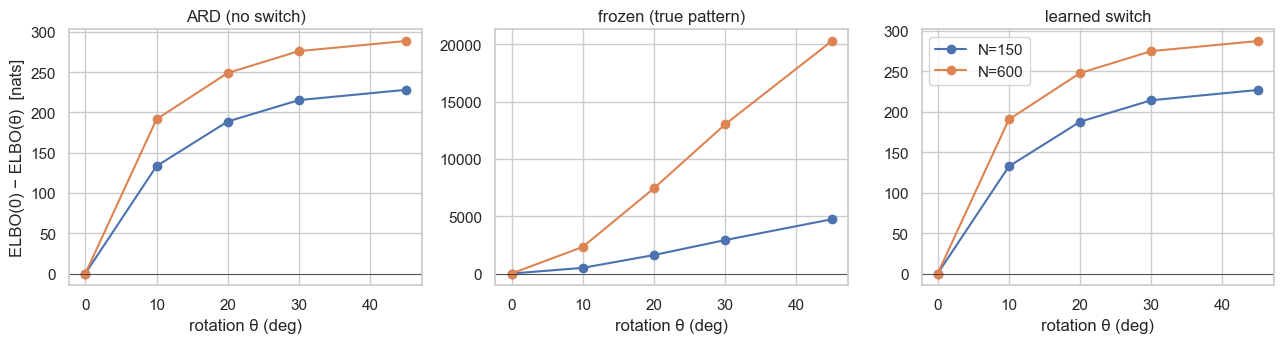

In [16]:
fig, axes = plt.subplots(1, len(q5.arm.unique()), figsize=(13, 3.6), sharey=False)
for ax, (arm, d) in zip(axes, q5.groupby("arm")):
    for N, dn in d.groupby("N"):
        g = dn.groupby("theta")["gap"].mean()
        ax.plot(g.index, g.values, "o-", label=f"N={N}")
    ax.set_title(arm); ax.set_xlabel("rotation θ (deg)"); ax.axhline(0, color="k", lw=.5)
axes[0].set_ylabel("ELBO(0) − ELBO(θ)  [nats]"); axes[-1].legend()
plt.tight_layout(); plt.show()

In [17]:
for arm, oc in ex.decide_q5(q5).items():
    outcome(oc, title=f"Observed outcome [{arm}]")

> **Observed outcome [ARD (no switch)]: O3** — GROWS SLOWER THAN N: gap 228 -> 288 (x1.3 for x4 samples): a penalty, but not likelihood-level identification.

> **Observed outcome [frozen (true pattern)]: O2** — GROWS LIKE N: gap 4736 -> 20280 nats (x4.3 for x4 samples). The split is pinned at likelihood level.

> **Observed outcome [learned switch]: O3** — GROWS SLOWER THAN N: gap 227 -> 288 (x1.3 for x4 samples): a penalty, but not likelihood-level identification.

## Q6 — One sharing rate for the whole model, or one per factor?

**Why we ask.** A single $\pi$ answers ‘are this dataset's factors mostly shared?’; a per-factor $\pi_k$ answers ‘is
factor $k$ shared?’ — but $\pi_k$ is learned from only $M$ switches. We need to know if the finer version is worth
the extra uncertainty.

**Setup.**

- **View counts** $M\in\{2,4,8\}$, same pattern family as Q3, this level's settings.
- Fit the view switch twice: with **one global $\pi$** and with **one $\pi_k$ per factor**.
- **Repeats.** 5 seeds per $M$.

**What we fit.** View switch (fixed slab), global $q(\pi)=\mathrm{Beta}(1+\sum_{m,k}\mathbb E h_{mk},\,1+MK-\sum\mathbb E h_{mk})$
vs per-factor $q(\pi_k)=\mathrm{Beta}(1+\sum_m\mathbb E h_{mk},\,1+M-\sum_m\mathbb E h_{mk})$.

**What we measure.**

- **Switch AUC** in both modes (does per-factor recover the pattern any better?).
- **$\mathrm{sd}(\pi_k)$** — how uncertain the per-factor rate is (large when $M$ is small).
- **Separation** = mean $\mathbb E[\pi_k]$ over shared factors minus over private factors.

**How to read the answer** (the rule the code applies, fixed before the run):

| Outcome | If we see | It would mean | So we |
|---|---|---|---|
| **O1** Either works | $\mathrm{sd}(\pi_k)<0.15$ at $M\le4$ and no AUC gain | per-factor is certain enough and costs nothing | choose by interpretability |
| **O2** Use one global $\pi$ | $\mathrm{sd}(\pi_k)\ge0.15$ at $M\le4$ and no AUC gain | per-factor rates are noise at realistic $M$ | use a single $\pi$ |
| **O3** Per-factor helps | switch AUC gain $\ge0.03$ at some $M$ | the finer rate improves recovery there | keep $\pi_k$ where it helps |

*Thresholds live in `sharedness/experiments.py`; the full statement is in notebook 00.*

In [18]:
q6 = ex.run_q6(LEVEL, seeds=SEEDS)
q6.to_csv(os.path.join(RESULTS, f"{LEVEL}_q6.csv"), index=False)
q6.groupby(["M", "mode"])[["auc_h", "decisive_h", "pi_sd", "pi_sep", "min_corr"]].mean()

auc_h  decisive_h  pi_sd  pi_sep  min_corr
M mode                                                  
2 global      0.600         1.0  0.124     NaN     0.783
  per_factor  0.600         1.0  0.198   0.050     0.783
4 global      0.850         1.0  0.093     NaN     0.755
  per_factor  0.850         1.0  0.171   0.367     0.755
8 global      0.874         1.0  0.053     NaN     0.562
  per_factor  0.876         1.0  0.127   0.530     0.563

In [19]:
outcome(ex.decide_q6(q6))

> **Observed outcome: O2** — USE ONE GLOBAL PI: per-factor pi_k is uncertain at M <= 4 (posterior sd 0.18) and does not improve recovery (largest AUC gain +0.00).

'O2'

## Summary of this notebook

The outcome lines above are collected, with the other levels, in `notebooks_sharedness/REPORT.md`.